# Reconstructing Spline from Measurement Data

In [1]:


import requests
import pandas as pd

import bspline_python
from bspline_python import *
from dotmap import DotMap

%load_ext autoreload
%aimport -bspline_python
%autoreload 1

## Read Data from API

In [2]:


api_url='https://xray-api.renecol.org'
token='DLkevyX247TBgr5Jl7fvGRSO03k3YG'
image_suffix='/api/imagedata/'
response = requests.get(headers={'Authorization': 'Bearer ' + token},url=api_url+image_suffix, params={'detailed':True, 'complete':True}).json()
df = pd.DataFrame(response)


df2 = df[['id','uuid','img','patient_id','measure_dataset','referring_patient','img_type','acquisition_date']]
# filter those rows where measure_dataset is not an empty list
df3 = df2[df2['measure_dataset'].map(lambda d: len(d)) > 0]

# unpack measure_dataset column and combine it with the rest of df3, renaming the columns appropriately 
df4 = pd.concat([df3.drop(columns=['measure_dataset']), df3['measure_dataset'].apply(pd.Series)], axis=1)
# transfer to long format
df4b=df4.melt(id_vars=['id','uuid','img','patient_id','referring_patient','img_type','acquisition_date'], value_name='measure_dataset', var_name='measure_dataset_index').dropna(subset=['measure_dataset'])

df4c = pd.concat([df4b.drop(columns=['measure_dataset']), df4b['measure_dataset'].apply(pd.Series)['data'], df4b['measure_dataset'].apply(pd.Series)['uuid'].rename('m_uuid')], axis=1)
df4d = pd.concat([df4c.drop(columns=['data']), df4c['data'].apply(pd.Series)], axis=1)
df4d.to_pickle('data/df4d_spine_measurements.pkl')

In [3]:
# save id, uuid, img_type, patient_id, measure_dataset_indices and img url to json
df['measurement_indices']=df['measure_dataset'].apply(lambda m: [mi['id'] for mi in m] if isinstance(m, list) else [])
df.drop(columns=['measure_dataset','upload_user','referring_patient','patient_id_integrity_check','public','created_at','last_modified','image_hash']).to_json('data/df_keys.json',orient='records')

## Alternatively Read Data from Pickle

In [2]:
df4d=pd.read_pickle('data/df4d_spine_measurements.pkl')

## selective reconstruction and plotting

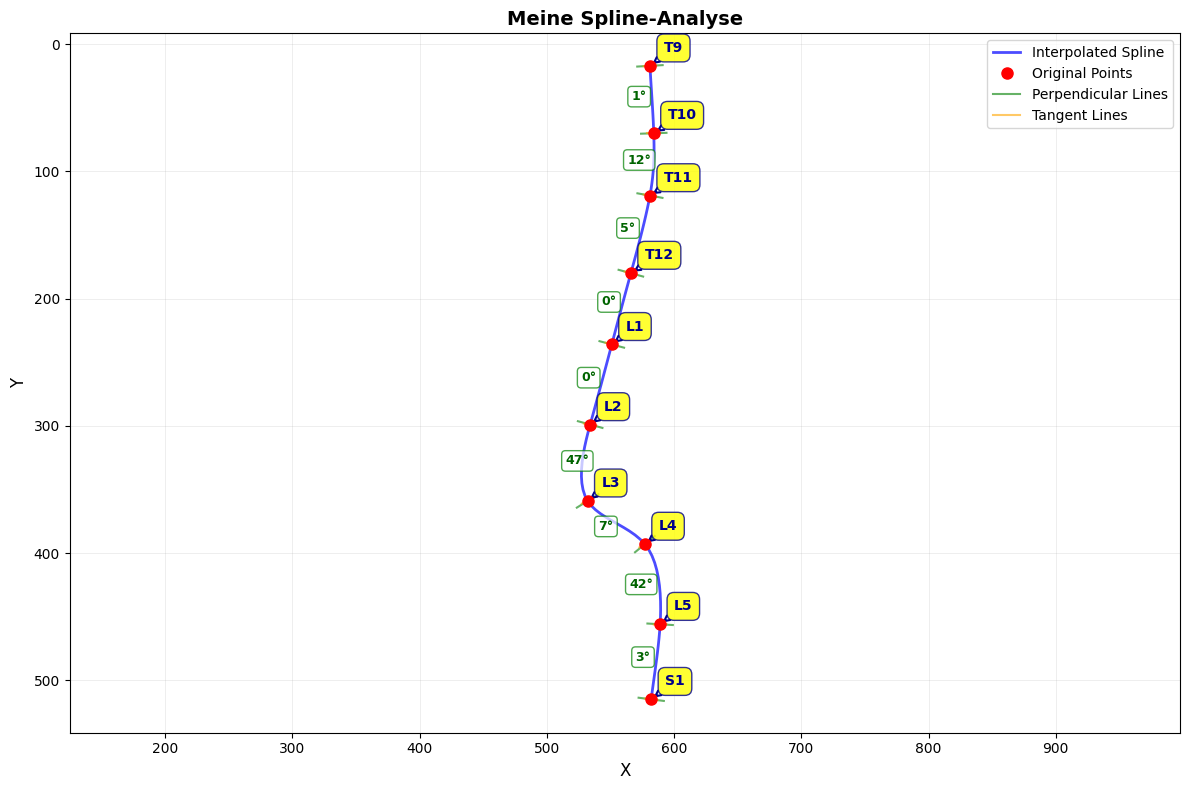

In [4]:
# Retreive node information for a specific measurement
m = df4d.iloc[750,9]

nodes = [(i['x'],i['y']) for i in m['stateObject']['nodes']]
m['stateObject']

selected_vertebra = spine_labels[m['stateObject']['vertebra_range'][0]:m['stateObject']['vertebra_range'][1]+1]


spline=interpolate_bspline(nodes)
nodesmap=[DotMap(i) for i in m['stateObject']['nodes']]
mapped=map_nodes_to_spline_and_keys(nodesmap,selected_vertebra,spline)
node_idcs=[i.spline_idx for i in mapped]
tangents = calculate_tangents(nodes, [], length=10)
perp_lines = get_perpendicular_lines_at_indices(spline, length=20, indices=node_idcs)
    



# Plot anzeigen
plot_spline_and_lines(
    original_points=nodes,
    interpolated_points=spline,
    lines=perp_lines,
    tangents=tangents,
    mapped_nodes=mapped,
    show_angles=True,
    invert_yaxis=True,
    title="Meine Spline-Analyse"
)


In [5]:
m['stateObject']

{'nodes': [{'x': 581, 'y': 17, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 584, 'y': 70, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 581, 'y': 119, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 566, 'y': 180, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 551, 'y': 236, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 534, 'y': 299, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 532, 'y': 359, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 577, 'y': 393, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 589, 'y': 456, 'fill': 'blue', 'type': 'Circle', 'radius': 4},
  {'x': 582, 'y': 515, 'fill': 'blue', 'type': 'Circle', 'radius': 4}],
 'cobbLines': [{'x1': 518,
   'x2': 645,
   'y1': 444,
   'y2': 396,
   'mode': 'Cobb-regional'},
  {'x1': 462.9983996247396,
   'x2': 618.9983996247396,
   'y1': 191,
   'y2': 219,
   'mode': 'Cobb-regional'},
  {'x1': 533.7770664998843,
   'x2': 625.7770664998843,
   'y1': 126.66

## Selective reconstruction from 3 measurement datasets

In [41]:
# get 3 measurements with the same id
id_to_select = df4d.iloc[28,0]
measurements_to_reconstruct = df4d[df4d['id'] == id_to_select].iloc[:3,9]

def reconstruct_datasets(measurements_to_reconstruct):
    datasets = []
    for idx,m in measurements_to_reconstruct.items():
        nodes = [(i['x'],i['y']) for i in m['stateObject']['nodes']]
        selected_vertebra = spine_labels[m['stateObject']['vertebra_range'][0]:m['stateObject']['vertebra_range'][1]+1]
        spline=interpolate_bspline(nodes)
        nodesmap=[DotMap(i) for i in m['stateObject']['nodes']]
        mapped=map_nodes_to_spline_and_keys(nodesmap,selected_vertebra,spline)
        node_idcs=[i.spline_idx for i in mapped]
        tangents = calculate_tangents(nodes, [], length=10)
        perp_lines = get_perpendicular_lines_at_indices(spline, length=20, indices=node_idcs)
        segmentalAngles=generate_COBB_angles_from_tangents(tangents,mapped, perp_lines, mode='segmental')
        regionalAngles=generate_COBB_angles_from_tangents(tangents,mapped, perp_lines, mode='regional_S1')
        lumbarSegmentalAngles=[a for a in segmentalAngles if a['from_label'] in ['T12','L1','L2','L3','L4','L5'] and a['to_label'] in ['L1','L2','L3','L4','L5','S1']]
        datasets.append({
            'original_points': nodes,
            'interpolated_points': spline,
            'lines': perp_lines,
            'tangents': tangents,
            'mapped_nodes': mapped,
            'label': f'Measurement {idx+1}',
            'regionalAngles': regionalAngles,
            'lumbarSegmentalAngles':lumbarSegmentalAngles
        })
    return datasets
        
datasets = reconstruct_datasets(
    measurements_to_reconstruct
)
plot_spline_and_lines_multiple(datasets, title=f"Reconstruction for ID {id_to_select}") 

Nicht genügend Extrempunkte für Cobb-Winkelberechnung gefunden.


IndexError: list index out of range

In [47]:
import pprint
pprint.pprint(df4d.iloc[389,9])

{'angles': [],
 'calibration': {},
 'stateObject': {'cobbLines': [], 'nodes': [], 'vertebra_range': [16, 25]}}


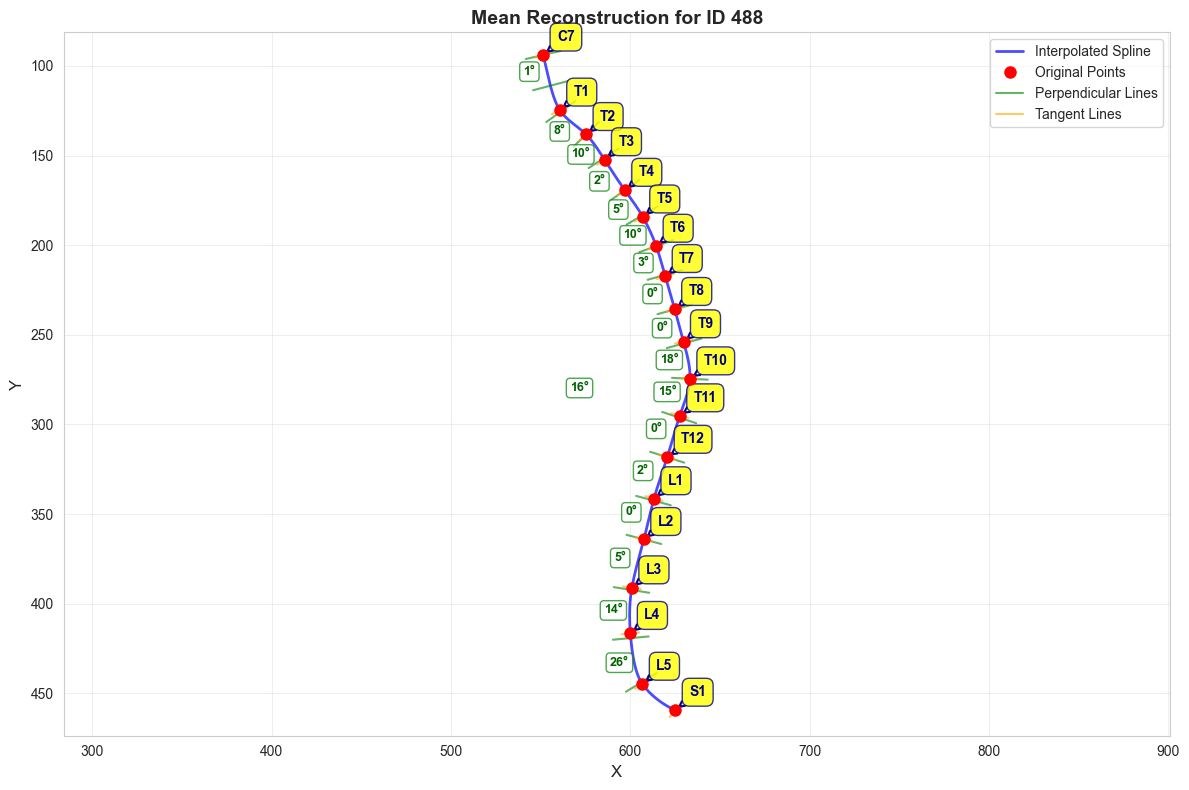

In [31]:
# form one mean dataset for all 3 measurements and plot again
mean_nodes = {}

for d in datasets:
    points=d['mapped_nodes']
    mapped_keys=[mn.label for mn in points]
    for mk in mapped_keys:
        if mk not in mean_nodes:
            mean_nodes[mk] = []
        node = next((mn for mn in points if mn.label == mk), None)
        if node:
            mean_nodes[mk].append((node.x, node.y, node.spline_idx if hasattr(node, 'spline_idx') else None))
mean_nodes_avg = {mk: (sum(x for x, y,_ in coords) / len(coords), sum(y for x, y,_ in coords) / len(coords)) for mk, coords in mean_nodes.items()}
mean_node_idcs = [sum([spline_idx for x, y, spline_idx in coords if spline_idx is not None]) // len(coords) for mk, coords in mean_nodes.items()]
var_nodes = {mk: (sum((x - mean_nodes_avg[mk][0]) ** 2 for x, y,_ in coords) / len(coords), sum((y - mean_nodes_avg[mk][1]) ** 2 for x, y,_ in coords) / len(coords)) for mk, coords in mean_nodes.items()}
mean_nodes_list = [DotMap(x=coord[0], y=coord[1], label=mk) for mk, coord in mean_nodes_avg.items()]
# sort mean_nodes_list by label according to spine_labels order
mean_nodes_list.sort(key=lambda mn: spine_labels.index(mn.label) if mn.label in spine_labels else -1)
mean_spline = interpolate_bspline([(mn.x, mn.y) for mn in mean_nodes_list])
#mean_node_idcs = [i for i, mn in enumerate(mean_nodes_list)]
mean_tangents = calculate_tangents([(mn.x, mn.y) for mn in mean_nodes_list], [], length=10)
mean_perp_lines = get_perpendicular_lines_at_indices(mean_spline, length=20, indices=mean_node_idcs)
plot_spline_and_lines(
    original_points=[(mn.x, mn.y) for mn in mean_nodes_list],
    interpolated_points=mean_spline,
    lines=mean_perp_lines,
    tangents=mean_tangents,
    mapped_nodes=mean_nodes_list,
    show_angles=True,
    invert_yaxis=True,
    title=f"Mean Reconstruction for ID {id_to_select}"
)

In [34]:
# transform datasets mapped nodes to dataframe with row indices as labels and columns x, y, spline_idx
mapped_dfs = []
for idx,d in enumerate(datasets):
    mapped_nodes = d['mapped_nodes']
    mapped_df = pd.DataFrame([(mn.label, mn.x, mn.y, mn.spline_idx if hasattr(mn, 'spline_idx') else None) for mn in mapped_nodes], columns=['label', 'x', 'y', 'spline_idx'])
    mapped_df['measurement'] = idx
    mapped_dfs.append(mapped_df)
# concatenate mapped_dfs and calculate mean x, y, spline_idx for each label
concatenated_df = pd.concat(mapped_dfs)
# sort concatenated_df by label according to spine_labels order and perform statistical analysis (mean, variance and t-test) for each label
concatenated_df['label'] = pd.Categorical(concatenated_df['label'], categories=spine_labels, ordered=True)
concatenated_df.sort_values('label', inplace=True)

In [26]:

stats_df = concatenated_df.groupby('label').agg({'x': ['mean', 'std'], 'y': ['mean', 'std'], 'spline_idx': ['mean', 'std']})
stats_df.columns = ['_'.join(col) for col in stats_df.columns]
stats_df.reset_index(inplace=True)
print(stats_df)

   label      x_mean      x_std      y_mean      y_std  spline_idx_mean  \
0     C0         NaN        NaN         NaN        NaN              NaN   
1     C1         NaN        NaN         NaN        NaN              NaN   
2     C2         NaN        NaN         NaN        NaN              NaN   
3     C3         NaN        NaN         NaN        NaN              NaN   
4     C4         NaN        NaN         NaN        NaN              NaN   
5     C5         NaN        NaN         NaN        NaN              NaN   
6     C6         NaN        NaN         NaN        NaN              NaN   
7     C7  551.396991        NaN   93.877592        NaN         0.000000   
8     T1  560.677536   3.755864  124.574118  13.330210         5.500000   
9     T2  575.381278   5.377887  138.204157  10.235985        11.000000   
10    T3  585.619961   3.560635  152.245309   7.686979        21.333333   
11    T4  596.957410   5.116045  169.331729   8.085682        31.666667   
12    T5  606.982101   5.

Es zeigt sich bereite bei einem Datensatz eine gewaltige Abweichung der Nodes, was auf eine fehlerhafte Labelzuordnung hindeutet.

### Neu-Labeln anhand kMeans Clustering

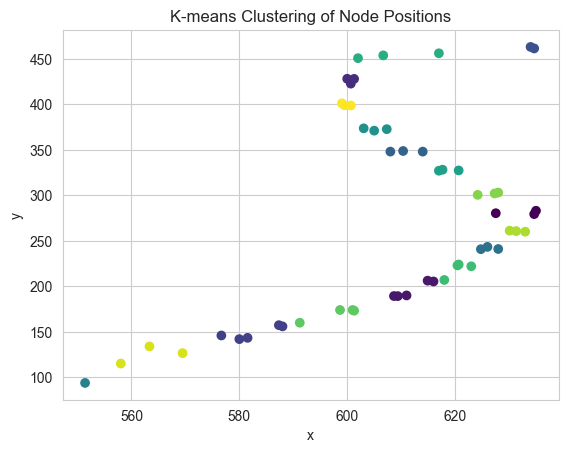

In [38]:
# take concatenated_df and perform k-means clustering on x and y columns to identify potential outliers in the node positions, using 2 clusters and plotting the results
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
kmeans = KMeans(n_clusters=len(selected_vertebra), random_state=0).fit(concatenated_df[['x', 'y']])
concatenated_df['cluster'] = kmeans.labels_
plt.scatter(concatenated_df['x'], concatenated_df['y'], c=concatenated_df['cluster'], cmap='viridis')
plt.xlabel('x')
plt.ylabel('y')
plt.title('K-means Clustering of Node Positions')
plt.show()

In [33]:
# take kmeans cluster centers, sorted by y-coordinate and assign them a spine label, based on selected_vertebra and the order of the cluster centers. Then, compare the assigned labels with the original labels in concatenated_df to identify potential mislabeling.
cluster_centers = kmeans.cluster_centers_
cluster_centers_df = pd.DataFrame(cluster_centers, columns=['x', 'y'])
cluster_centers_df['y_rank'] = cluster_centers_df['y'].rank()
cluster_centers_df.sort_values('y_rank', inplace=True)
cluster_centers_df['assigned_label'] = selected_vertebra[:len(cluster_centers_df)]
print(cluster_centers_df[['x', 'y', 'assigned_label']])

            x           y assigned_label
1  627.000000   12.000000            T12
5  603.333333   65.666667             L1
3  573.333333  117.333333             L2
2  541.666667  176.000000             L3
6  519.000000  237.333333             L4
4  517.666667  303.000000             L5
0  545.166667  390.333333             S1


In [42]:

# Merge assigned labels back to concatenated_df based on proximity to cluster centers y coordinate, and create a new column 'assigned_label' in concatenated_df with the assigned labels. Then, compare the assigned labels with the original labels in concatenated_df to identify potential mislabeling.  
def assign_cluster_label(row):
    distances = ((cluster_centers_df.loc[:,'y'] - row['y']) ** 2)
    closest_cluster = distances.argmin()
    return cluster_centers_df.iloc[closest_cluster]['assigned_label']
concatenated_df['assigned_label'] = concatenated_df.apply(assign_cluster_label, axis=1)
# Compare assigned labels with original labels
concatenated_df['label_match'] = concatenated_df['label'] == concatenated_df['assigned_label']


In [43]:
# Group by measurement and calculate the number of matches and mismatches
concatenated_df.groupby('measurement').agg({'label_match': 'sum'})

,label_match
measurement,
0,17
1,18
2,2


In [4]:
# get the direction of label mismatch by transforming the assigned and original labels to their corresponding indices in spine_labels and calculating the difference. Then, plot a histogram of the label mismatch directions to identify any systematic mislabeling patterns.
def label_to_index(label):
    if label in spine_labels:
        return spine_labels.index(label)
    else:        return None
    
    

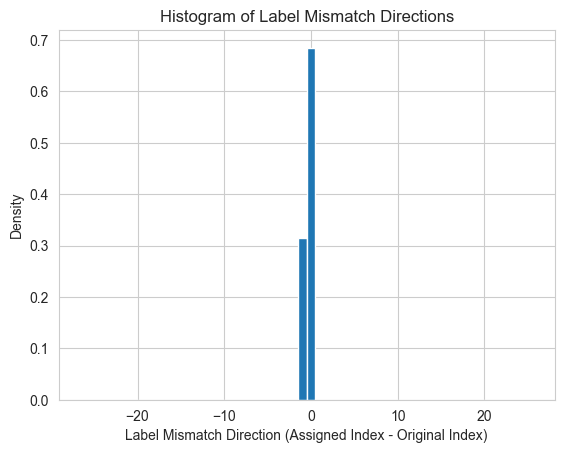

In [45]:
concatenated_df['label_index'] = concatenated_df['label'].apply(label_to_index)
concatenated_df['assigned_label_index'] = concatenated_df['assigned_label'].apply(label_to_index)
concatenated_df['label_index']=pd.to_numeric(concatenated_df['label_index'], errors='coerce')
concatenated_df['assigned_label_index']=pd.to_numeric(concatenated_df['assigned_label_index'], errors='coerce')
concatenated_df['label_mismatch_direction'] = concatenated_df['assigned_label_index'] - concatenated_df['label_index']
plt.hist(concatenated_df['label_mismatch_direction'].dropna(), bins=np.arange(-len(spine_labels), len(spine_labels)+1)-0.5, density=True)
plt.xlabel('Label Mismatch Direction (Assigned Index - Original Index)')
plt.ylabel('Density')
plt.title('Histogram of Label Mismatch Directions')
plt.show()

In [22]:
stats_df = concatenated_df.groupby('label').agg({'x': ['mean', 'std'], 'y': ['mean', 'std'], 'spline_idx': ['mean', 'std']})
stats_df.columns = ['_'.join(col) for col in stats_df.columns]
mean_std = stats_df[['x_std', 'y_std']].mean(axis=1).mean()
print('Durchschnittliche Std bei Verwendung der Original-Label: %f' % mean_std)
stats_df2 = concatenated_df.groupby('assigned_label').agg({'x': ['mean', 'std'], 'y': ['mean', 'std'], 'spline_idx': ['mean', 'std']})
stats_df2.columns = ['_'.join(col) for col in stats_df2.columns]
mean_std_assigned = stats_df2[['x_std', 'y_std']].mean(axis=1).mean()
print('Durchschnittliche Std bei Verwendung der k-means zugewiesenen Label: %f' % mean_std_assigned)

Durchschnittliche Std bei Verwendung der Original-Label: 7.992670
Durchschnittliche Std bei Verwendung der k-means zugewiesenen Label: 2.051456


Somit ist gezeigt, dass ein Datensatz ausreicht, um die Statistik zu verzerren. Ursache ist das Verrutschen beim Labeln.

## Whole Dataset Correction
Take all the measurements, do kMeans Clustering and assign new labels

In [49]:
# select measurements_to_reconstruct where the dict item with key "angles" contains at least one item

measurements_to_reconstruct[measurements_to_reconstruct.apply(lambda m: len(m['angles']) > 0)]

28     {'angles': [{'cobbType': 'Spline', 'cobbAngle'...
750    {'angles': [{'cobbType': 'Spline', 'cobbAngle'...
Name: xray_measurement_data, dtype: object

In [5]:
from sklearn.cluster import KMeans
def label_to_index(label):
    if label in spine_labels:
        return spine_labels.index(label)
    else:        
        return None

In [55]:

# saving dataset idx, img id and label error
to_shift_measurements=[]    
empty_measurements = []

unique_img_ids = list(df4d['id'].unique())
ids_to_process = unique_img_ids
for id in ids_to_process:
    measurements_to_reconstruct = df4d[df4d['id'] == id].iloc[:3,9]
    e_mlist = list(measurements_to_reconstruct[measurements_to_reconstruct.apply(lambda m: len(m['angles']) == 0)].index)
    if len(e_mlist)>0:
        for e in e_mlist:
            empty_measurements.append({'id':e,
                                       'm_uuid':df4d.loc[e,'m_uuid'],
                                     'uuid':df4d.loc[e,'uuid'],
                                         'url':df4d.loc[e,'img'],
                                      'error': 'empty',
                                      'shift':0})        
        measurements_to_reconstruct = measurements_to_reconstruct[measurements_to_reconstruct.apply(lambda m: len(m['angles']) > 0)]
    measurement_datasets = reconstruct_datasets(measurements_to_reconstruct)
    mapped_dfs = []
    for idx,d in enumerate(measurement_datasets):
        mapped_nodes = d['mapped_nodes']
        mapped_df = pd.DataFrame([(mn.label, mn.x, mn.y, mn.spline_idx if hasattr(mn, 'spline_idx') else None) for mn in mapped_nodes], columns=['label', 'x', 'y', 'spline_idx'])
        mapped_df['measurement'] = idx
        mapped_dfs.append(mapped_df)
    # concatenate mapped_dfs and calculate mean x, y, spline_idx for each label
    concatenated_df = pd.concat(mapped_dfs)
    # sort concatenated_df by label according to spine_labels order and perform statistical analysis (mean, variance and t-test) for each label
    concatenated_df['label_index']=concatenated_df['label'].apply(label_to_index)
    
    # count the measurements for each labeled vertebra, sort out 0 values and confirm that the most bottom vertebra has more than one measurements. Otherwise print out warning and break.
    label_counts = concatenated_df['label_index'].value_counts().sort_index()
    label_counts_nonzero = label_counts[label_counts > 0]
    if label_counts_nonzero.iloc[-1] <= 1:
        print(f'Warning: The most bottom vertebra for ID {id} has no measurements or only one measurement. This may indicate a labeling issue. Skipping this ID.')
        continue    
                
    v_min=int(concatenated_df['label_index'].min())
    v_max=int(concatenated_df['label_index'].max())
    
    spine_length = int(v_max-v_min)
    kmeans = KMeans(n_clusters=spine_length+1, random_state=0).fit(concatenated_df[['x', 'y']])
    concatenated_df['cluster'] = kmeans.labels_
    cluster_centers = kmeans.cluster_centers_
    cluster_centers_df = pd.DataFrame(cluster_centers, columns=['x', 'y'])
    cluster_centers_df['y_rank'] = cluster_centers_df['y'].rank()
    cluster_centers_df.sort_values('y_rank', inplace=True)
    cluster_centers_df['assigned_label'] = spine_labels[v_min:v_max+1]
    
    def assign_cluster_label(row):
        distances = ((cluster_centers_df.loc[:,'y'] - row['y']) ** 2)
        closest_cluster = distances.argmin()
        return cluster_centers_df.iloc[closest_cluster]['assigned_label']
    
    concatenated_df['assigned_label'] = concatenated_df.apply(assign_cluster_label, axis=1)
    # Compare assigned labels with original labels
    concatenated_df['label_match'] = concatenated_df['label'] == concatenated_df['assigned_label']
    concatenated_df['assigned_label_index'] = concatenated_df['assigned_label'].apply(label_to_index)
    concatenated_df['label_index']=pd.to_numeric(concatenated_df['label_index'], errors='coerce')
    concatenated_df['assigned_label_index']=pd.to_numeric(concatenated_df['assigned_label_index'], errors='coerce')
    concatenated_df['label_mismatch_direction'] = concatenated_df['assigned_label_index'] - concatenated_df['label_index']
    
    # Group by measurement and calculate the number of matches and mismatches
    matching_measurements=list(concatenated_df.groupby('measurement').agg({'label_match': 'sum'}).values.flatten())
    achievable_matches = max(matching_measurements)
    match_deviation = [(achievable_matches - m)/achievable_matches for m in matching_measurements]
    to_recalc_measurements = [i for i, d in enumerate(match_deviation) if d > 0.5]
    measurement_indices_to_recalc = [measurements_to_reconstruct.index[i] for i in to_recalc_measurements]
    matching_measurements=[str(m) for m in matching_measurements]
    recalc_string=''
    if len(measurement_indices_to_recalc) > 0:
        recalc_string = f'Measurements to recalculate: {to_recalc_measurements} => Indices: {measurement_indices_to_recalc}.  '
    
        print(f'ID: {id}: From {spine_labels[v_min]} to {spine_labels[v_max]}, assigned from {cluster_centers_df.iloc[0,3]} to {cluster_centers_df.iloc[-1,3]}. Matchings: {("|").join(matching_measurements)}. {recalc_string}')
        
        recalc_urls = [f'https://xray-annotator.renecol.org/?relayto={df4d.loc[m_id,"uuid"]}  --> look there for Measurement UUID {df4d.loc[m_id,"m_uuid"]}' for m_id in measurement_indices_to_recalc]
        print(recalc_urls)
    else:
        print(f'ID: {id}: OK.')
    
    for recalc_idx,mi in zip(to_recalc_measurements,measurement_indices_to_recalc):
        # get the direction of the  label shift error
        shift_error = concatenated_df[concatenated_df['measurement']==recalc_idx]['label_mismatch_direction'].mode()[0]
        to_shift_measurements.append({'id':mi,
                                     'm_uuid':df4d.loc[mi,'m_uuid'],
                                     'uuid':df4d.loc[mi,'uuid'],
                                         'url':df4d.loc[mi,'img'],
                                      'error': 'shift',
                                      'shift':shift_error})
        print(f'Found shift of {shift_error} to measurement index (=dataframe idx) {mi} for ID {id}')
       

ID: 488: From C7 to S1, assigned from C7 to S1. Matchings: 17|18|2. Measurements to recalculate: [2] => Indices: [722].  
['https://xray-annotator.renecol.org/?relayto=3cda32c7-b3d3-4538-9256-2b78de347ee9  --> look there for Measurement UUID eb7f0dfb-e9e2-4986-b6a5-3f6ac45dc008']
Found shift of -1 to measurement index (=dataframe idx) 722 for ID 488
ID: 487: OK.
ID: 486: OK.
ID: 485: OK.
ID: 484: From C7 to S1, assigned from C7 to S1. Matchings: 0|18|1. Measurements to recalculate: [0, 2] => Indices: [4, 726].  
['https://xray-annotator.renecol.org/?relayto=7e2b5c1a-0300-4dca-80bb-37a5c8b5508e  --> look there for Measurement UUID f87a3f20-7e28-49fe-988c-2f0bdf6b0845', 'https://xray-annotator.renecol.org/?relayto=7e2b5c1a-0300-4dca-80bb-37a5c8b5508e  --> look there for Measurement UUID 0869358c-d116-4d0d-938b-5ffbf94a2f16']
Found shift of -1 to measurement index (=dataframe idx) 4 for ID 484
Found shift of -1 to measurement index (=dataframe idx) 726 for ID 484
ID: 483: OK.
ID: 482: OK.

In [56]:
# create a dataframe with the to_shift_measurements and empty_measurements and save it to a json file
result_df = pd.DataFrame(to_shift_measurements + empty_measurements).set_index('id')
result_df.to_json('data/label_errors.json', orient='index')
    
        

In [3]:
result_df=pd.read_json('data/label_errors.json', orient='index')

## Apply the corrections to original data
We are going to apply the shifting and will delete the empty measurements

In [24]:
def correct_measurement_label_shift(data, shift_correction):
    angles=[]
    for angle in data['angles']:
        v_lower = angle['cobbAngle']['vertebra_lower']
        v_upper = angle['cobbAngle']['vertebra_upper']
        v_lower_idx=label_to_index(v_lower)
        v_upper_idx=label_to_index(v_upper)
        if  (v_lower_idx==None) | (v_upper_idx==None):
            print(f'Leaving out regional CobbAngle, Upper: {v_upper}, Lower: {v_lower}')
            continue
        if ((v_lower_idx+shift_correction)>len(spine_labels)-1) | ((v_upper_idx+shift_correction)<0):
            print(f'Shift correction does not work for regional Cobb Angle, Upper: {v_upper}, Lower: {v_lower}')
            continue
        new_v_lower = spine_labels[int(v_lower_idx+shift_correction)]
        new_v_upper = spine_labels[int(v_upper_idx+shift_correction)]
        new_record = {**angle,'cobbAngle':{'angle':angle['cobbAngle']['angle'], 'vertebra_lower':new_v_lower, 'vertebra_upper':new_v_upper}}
        angles.append(new_record)
    so_vertebra_range = data['stateObject']['vertebra_range']
    new_vertebra_range = [n+shift_correction for n in so_vertebra_range]
    if (min(new_vertebra_range)>0) & max(new_vertebra_range)<len(spine_labels):
        new_stateObject = {**data['stateObject'], 'vertebra_range':new_vertebra_range}
    else:
        new_stateObject = data['stateObject']
    if len(angles)==0:
        angles=data['angles']
    new_data = {**data, 'angles':angles,'stateObject':new_stateObject}
    return new_data

df4d_corrected = df4d.copy()
# cast df4d_corrected column xray_measurement_data to column of dicts

correction_list=[]


for row in result_df.iterrows():
    idx=row[0]
    error_type = row[1]['error']
    print(f'Correcting {idx}')
    if error_type == 'shift':
        correction = correct_measurement_label_shift(df4d_corrected.loc[idx,'xray_measurement_data'], result_df.loc[idx,'shift']*-1)
        if len(correction)>0:
            correction_list.append({'id':idx,'xray_measurement_data':correction})
            print(f'Shifted {idx}')
        else:
            print(f'Didnt shift {idx}...You might consider reviewing this')

correction_series = pd.DataFrame(correction_list).set_index('id')
df4d_corrected.update(correction_series)

Correcting 722
Shift correction does not work for regional Cobb Angle, Upper: L1, Lower: S1
Shift correction does not work for regional Cobb Angle, Upper: L1, Lower: S1
Shift correction does not work for regional Cobb Angle, Upper: L5, Lower: S1
Shifted 722
Correcting 4
Shift correction does not work for regional Cobb Angle, Upper: T12, Lower: S1
Shift correction does not work for regional Cobb Angle, Upper: T12, Lower: S1
Shifted 4
Correcting 726
Shift correction does not work for regional Cobb Angle, Upper: L1, Lower: S1
Shift correction does not work for regional Cobb Angle, Upper: T12, Lower: S1
Shift correction does not work for regional Cobb Angle, Upper: L5, Lower: S1
Shifted 726
Correcting 733
Leaving out regional CobbAngle, Upper: T10, Lower: ?
Leaving out regional CobbAngle, Upper: T12, Lower: ?
Shift correction does not work for regional Cobb Angle, Upper: L5, Lower: S1
Shifted 733
Correcting 373
Shift correction does not work for regional Cobb Angle, Upper: T9, Lower: S1
Sh

In [26]:
df4d.compare(df4d_corrected)
df4d_corrected.to_pickle('data/df4d_corrected_spine_measurements.pkl')

## Bulk reconstruction
Reconstruct the spline measurements by using different interpolation technique than in xray-annotator

In [27]:
# Function to extract nodes, create spline, calculate tangents and report reconstructed regional and segmental angles. The return value is  a list comprising the reconstructed angles.
spine_labels = ['C0','C1','C2','C3','C4','C5','C6','C7','T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12','L1','L2','L3','L4','L5','S1']

def getReconstructedCobbAngles(xray_measurement_data):
    m=xray_measurement_data
    nodes = [(i['x'],i['y']) for i in m['stateObject']['nodes']]
    selected_vertebra = spine_labels[m['stateObject']['vertebra_range'][0]:m['stateObject']['vertebra_range'][1]+1]
    spline=interpolate_bspline(nodes)
    reconstructedAngles=[]
    if len(spline)>2:        
        nodesmap=[DotMap(i) for i in m['stateObject']['nodes']]
        mapped=map_nodes_to_spline_and_keys(nodesmap,selected_vertebra,spline)
        node_idcs=[i.spline_idx for i in mapped]
        tangents = calculate_tangents(nodes, [], length=10)
        perp_lines = get_perpendicular_lines_at_indices(spline, length=20, indices=node_idcs)
        segmentalAngles=generate_COBB_angles_from_tangents(tangents,mapped, perp_lines, mode='segmental')
        regionalAngles=generate_COBB_angles_from_tangents(tangents,mapped, perp_lines, mode='regional_S1')
        lumbarSegmentalAngles=[a for a in segmentalAngles if a['from_label'] in ['T12','L1','L2','L3','L4','L5'] and a['to_label'] in ['L1','L2','L3','L4','L5','S1']]
        
        for a in regionalAngles:
            r={'cobbAngle':{'angle':a['cobb_angle'],'vertebra_lower':a['to_label'],'vertebra_upper':a['from_label']}, 'upperLine': a['upperLine'], 'lowerLine': a['lowerLine'], 'lineColor': a['lineColor'],
               'cobbType':'reconstructed_regional'}
            reconstructedAngles.append(r)
        for a in lumbarSegmentalAngles:
            r={'cobbAngle':{'angle':a['cobb_angle'],'vertebra_lower':a['to_label'],'vertebra_upper':a['from_label']},
                            'upperLine': a['upperLine'], 'lowerLine': a['lowerLine'], 'lineColor': a['lineColor'],
               'cobbType':'reconstructed_segmental'}
            reconstructedAngles.append(r)
    return reconstructedAngles
    
df4d['reconstructedAngles']=df4d.iloc[:,9].apply(getReconstructedCobbAngles)
df4d_corrected['reconstructedAngles']=df4d_corrected.iloc[:,9].apply(getReconstructedCobbAngles)

In [28]:
def transform_df4d(df4d):
    df5 = pd.concat([df4d.drop(columns=['xray_measurement_data']), df4d['xray_measurement_data'].apply(pd.Series)], axis=1)
    # use df5 for subsequent analysis
    
    df5['nodes']= df5['stateObject'].apply(lambda so: [(i['x'],i['y']) for i in so['nodes']])
    df5a = df5.drop(columns=['calibration', 'stateObject','globalParams','referring_patient','acquisition_date'])
    df5b1 = pd.concat([df5a.drop(columns=['angles']), df5a['angles'].apply(pd.Series)], axis=1)
    df5b2 = pd.concat([df4d.drop(columns=['reconstructedAngles']), df4d['reconstructedAngles'].apply(pd.Series)],axis=1)
    df5b = pd.concat([df5b1,df5b2],axis=0).drop(columns=['reconstructedAngles','xray_measurement_data','referring_patient','acquisition_date'])
    
    df5c=df5b.melt(id_vars=['id','uuid','m_uuid','img','patient_id','img_type','nodes','measure_dataset_index'], value_name='angle_data', var_name='angle_index').dropna(subset=['angle_data'])
    # exclude rows where patient_id contains the word example
    df5c = df5c[~df5c['patient_id'].str.contains('example', case=False, na=False)]
    return df5c

df5c=transform_df4d(df4d)
df5c_corrected = transform_df4d(df4d_corrected)
df5c.to_pickle('data/df5c_with_reconstructed_angles.pkl')
df5c_corrected.to_pickle('data/df5c_corrected_with_reconstructed_angles.pkl')

Proceed with the comparing angles notebook